# MLP: Titanic Classification

A dense network predicts survival from passenger attributes. Preprocessing is fitted on training rows only. The labeled data are split into 916 training, 196 validation, and 197 test rows with seed 0. Rescue boat and body fields are excluded because they leak outcomes.

The outputs below are saved from local GPU training. Documentation builds render these saved outputs without running cells.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import jax
import numpy as np
import pandas as pd
import jaxsaw as js
from jaxsaw import models, training
from IPython.display import display, Image, Code
RUN = ROOT / 'runs' / 'gallery/titanic'
print(f"JAXsaw {js.__version__} · JAX {jax.__version__}")
print(jax.devices())

JAXsaw 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Architecture

Input `[B, features]`, output `[B, 2]` logits. Cross-entropy uses integer survival labels. The validation checkpoint is selected by loss; test results are evaluated after selection.

The definition below is the actual package implementation used by this run.

In [2]:
display(Code(inspect.getsource(models.MLP), language="python"))

class MLP(nn.Module):
    def __init__(self, in_features, hidden_sizes, out_features, *, rngs):
        super().__init__()
        widths = [in_features, *hidden_sizes]
        self.hidden = nn.ModuleList(
            [nn.Linear(a, b, rngs=rngs) for a, b in zip(widths[:-1], widths[1:], strict=True)]
        )
        self.head = nn.Linear(widths[-1], out_features, rngs=rngs)

    def forward(self, x):
        for layer in self.hidden:
            x = F.relu(layer(x))
        return self.head(x)

## Objective and optimization

Training uses an explicit step. Data iteration, evaluation, and artifact writing remain outside compiled computation.

In [3]:
display(Code(inspect.getsource(training.classifier_step), language="python"))

@jit
def classifier_step(model, optimizer, batch):
    x, y = batch

    def objective(candidate):
        logits = candidate(x)
        return F.cross_entropy(logits, y), (logits.argmax(-1) == y).sum()

    (loss, correct), grads = value_and_grad(objective, has_aux=True)(model)
    optimizer.step(grads)
    return {"loss": loss, "correct": correct, "count": y.size}

## Reproduce the run

Select one GPU before launching Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The recipe below creates a new run directory and does not overwrite completed results. Leave `TRAIN=False` to inspect an existing local run. Checkpoints are gitignored; this notebook retains the figures and metrics for publication.

In [4]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'titanic', '--download',
           '--output', str(RUN), *RECIPES['titanic']]
print(' '.join(part.replace(str(ROOT) + '/', '')
               for part in ['python', *command[1:]]))
if TRAIN:
    subprocess.run(command,cwd=ROOT,check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Run the recipe locally before refreshing notebook outputs.')
report = json.loads((RUN / 'report.json').read_text())
configuration = report['config']
display(pd.DataFrame([{'epochs':configuration['epochs'], 'batch_size':configuration['batch_size'],
                      'seed':configuration['seed'], 'training_examples':report['train_samples'],
                      'validation_examples':report['validation_samples'],
                      'test_examples':report['test_samples']}]))
print('Training device:',', '.join(report['devices']))

python -m examples.run titanic --download --output runs/gallery/titanic --epochs 100 --batch-size 64


,epochs,batch_size,seed,training_examples,validation_examples,test_examples
0,100,64,0,916,196,197


Training device: cuda:0 NVIDIA GeForce RTX 5090


## Training history

The figure reports actual epoch metrics. For supervised tasks, the checkpoint with the lowest validation loss is selected before test evaluation.

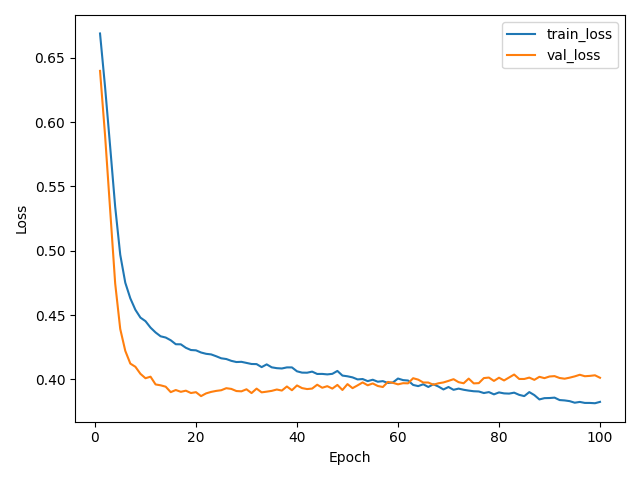

Selected epoch: 21


In [5]:
display(Image(filename=str(RUN / 'learning.png')))
if 'val_loss' in report['history'][0]:
    best_epoch = 1 + int(np.argmin([row['val_loss'] for row in report['history']]))
    print('Selected epoch:',best_epoch)

## Evaluation

The ROC and calibration panels complement accuracy. The majority baseline and subgroup sample counts prevent a single aggregate number from hiding class imbalance. Passenger/family relationships may cross this stratified split; this is not a family-held-out study.

In [6]:
metrics = {name:value for name,value in report.items()
           if name in ('test_loss','test_accuracy','majority_baseline_accuracy',
                       'persistence_baseline_mse','perplexity','test_auc','test_brier')}
if metrics:
    display(pd.DataFrame(list(metrics.items()),columns=['Metric','Value']))
print('Timed training loop (including validation/checkpoint work):',round(report['training_seconds'],2),'seconds')

,Metric,Value
0,test_loss,0.426506
1,test_accuracy,0.812183
2,majority_baseline_accuracy,0.619289
3,test_auc,0.846339
4,test_brier,0.135193


Timed training loop (including validation/checkpoint work): 3.28 seconds


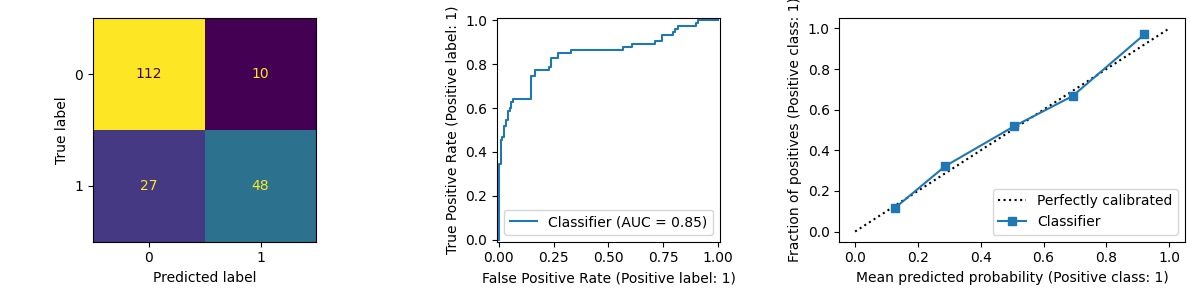

In [7]:
display(Image(filename=str(RUN / 'classification.png')))

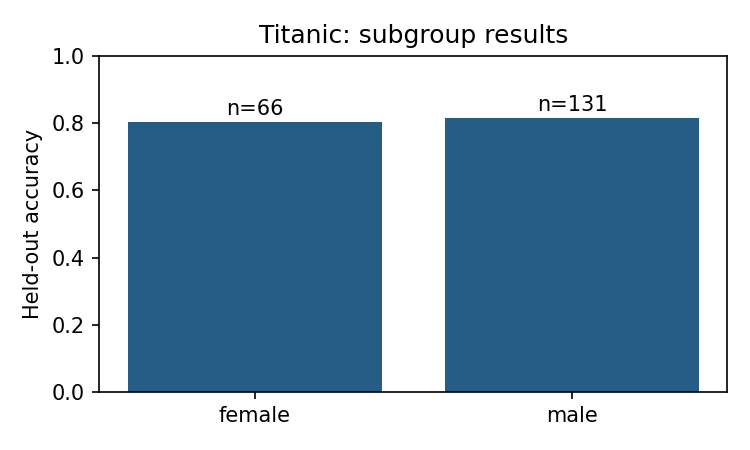

In [8]:
display(Image(filename=str(RUN / 'subgroups.png')))

In [9]:
display(pd.DataFrame(report['subgroups']).T.rename_axis('Subgroup'))

,count,accuracy
Subgroup,,
female,66.0,0.803030
male,131.0,0.816794


## Artifacts and further work

`report.json` records the configuration and measured outcomes. `data.json` records split/preprocessing information; `best.npz` (supervised tasks) and `last.npz` contain model/training state. Figures and predictions are saved separately. Use the checkpoint tutorial to restore an existing architecture.

Change one factor at a time, retain validation-based selection, and avoid choosing configurations or samples to improve the apparent test result.